# 02 · RTN vs. cRTN: scheduling a batch process (steelmaking)

**Where this sits in the chain:** *process model* → parameter identification → dimension reduction → grid/aggregator optimization.

Notebook 01 handled **continuous** processes. Many energy-intensive plants instead process discrete **batches** (in steelmaking, *heats*):

* **Uninterruptible tasks:** once a heat starts melting in the electric arc furnace (EAF), it must finish.
* **Waiting limits:** a hot heat may wait only so long before the next stage.
* **Flexible power:** the EAF can melt faster at high power or slower at low power.

This notebook compares two models of the same line:

| | Conventional **RTN** (Zhang et al. 2017) | **cRTN** (this thesis) |
|---|---|---|
| Decision | binary: *does task i for heat h start in slot t?* | continuous: *how long does task i run at each operating point in slot t?* |
| Grows with the number of heats? | yes, there is one set of tasks per heat | no, tasks are shared by all heats |
| Task durations | rounded up to whole slots | exact (fractions of a slot) |

*References:* thesis Ch. 2; R. Lyu et al., "Efficient Scheduling of Discrete Industrial Processes through Continuous Modeling," *IEEE Trans. Smart Grid*, in press; paper code: [Efficient-Scheduling-of-Discrete-Industrial-Processes](https://github.com/ruikelyu/Efficient-Scheduling-of-Discrete-Industrial-Processes). Plant data: X. Zhang et al., *IEEE Trans. Smart Grid* 8(1), 2017.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import indflex as fx
from indflex import viz

plt.rcParams["figure.dpi"] = 110

## 1. A one-furnace example: why rounding matters

One EAF of 1 MW must melt **2 heats** in 6 hours. A heat takes 2 h at nominal power, and the furnace can run between 50% and 133% of nominal power, so a heat takes between 1.5 h and 4 h. Two 6-hour price profiles:

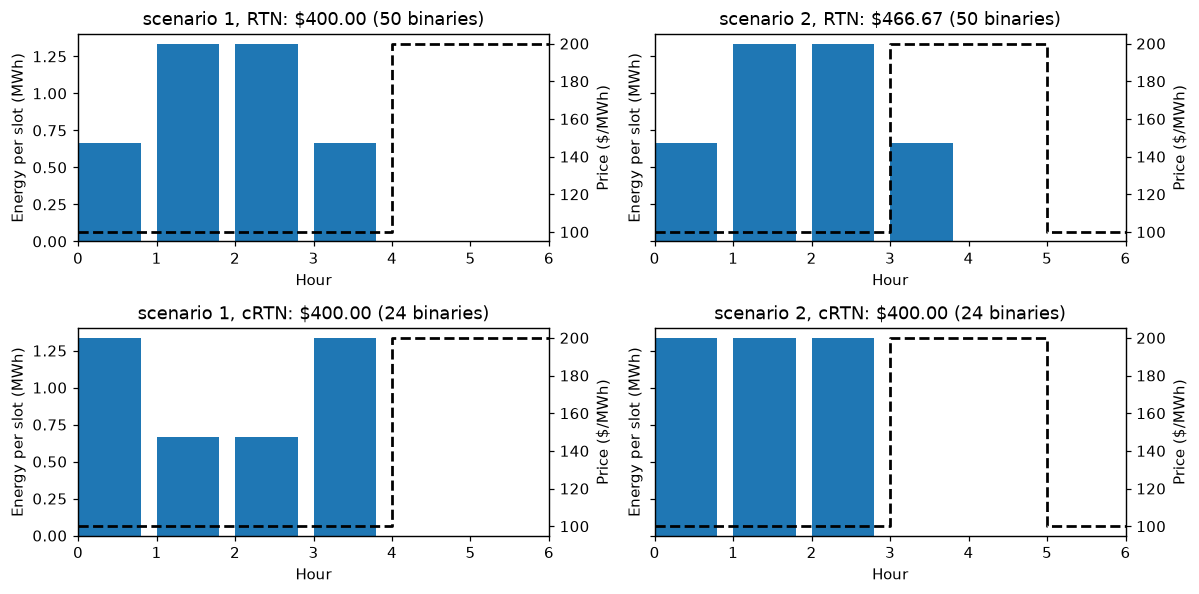

In [2]:
small = fx.load_batch_plant("eaf_small_case")
scenarios = {"scenario 1": np.array([100, 100, 100, 100, 200, 200.]),
             "scenario 2": np.array([100, 100, 100, 200, 200, 100.])}

fig, axes = plt.subplots(2, 2, figsize=(11, 5.5), sharey=True)
for col, (label, price) in enumerate(scenarios.items()):
    for row, (name, build) in enumerate([("RTN", fx.build_rtn), ("cRTN", fx.build_crtn)]):
        r = fx.solve(build(small, price, n_heats=2))
        viz.plot_schedule(r, price, ax=axes[row, col],
                          title=f"{label}, {name}: ${r.cost:,.2f} ({r.n_binary} binaries)")
        axes[row, col].get_legend().remove()
plt.tight_layout(); plt.show()

In **scenario 2**, the cheap hours are 0–2 and 5. The cRTN melts both heats at high power in the first three hours (1.5 h each, so two heats in 3 h) for **\$400**. The RTN can only start and finish tasks on slot boundaries: a 1.5 h melt is rounded up to 2 slots, so the second heat spills into an expensive hour and the cost rises to **\$466.67**. In the paper, this rounding error grows with the number of stages.

**Inside the two models.** The figure below follows the illustration in the thesis (Ch. 2, Figs. "Scheduling results of cRTN" and "Rounding error in the RTN model"). The RTN marks the furnace as busy for whole slots. The cRTN tracks the *progress* of the current heat, which rises from 0 to 1 and resets when the heat is output, so a heat can finish in the middle of a slot.

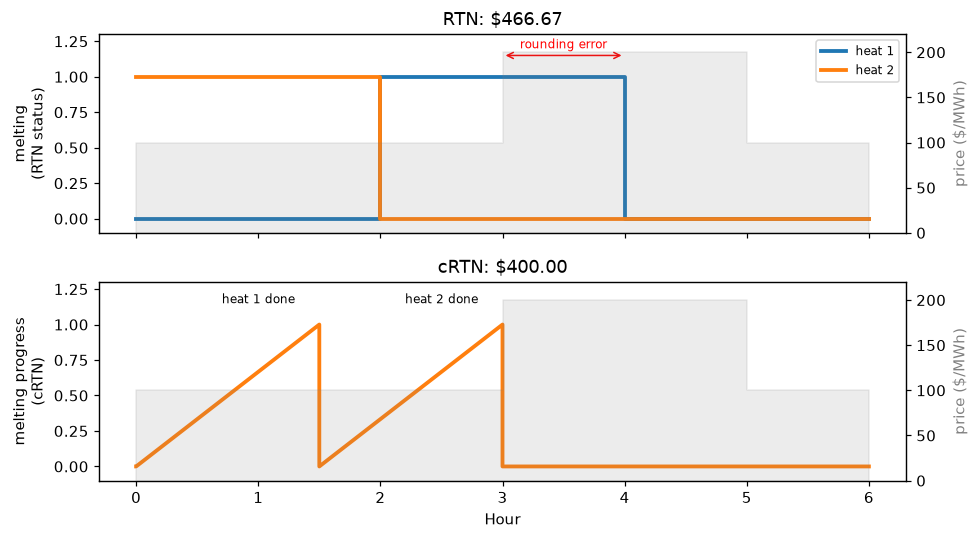

In [3]:
import pyomo.environ as pyo
from indflex.models import crtn_progress, heat_schedule

price = scenarios["scenario 2"]
m_rtn, m_crtn = fx.build_rtn(small, price, 2), fx.build_crtn(small, price, 2)
fx.solve(m_rtn); fx.solve(m_crtn)

fig, axes = plt.subplots(2, 1, figsize=(9, 5), sharex=True)
for ax in axes:  # price background
    ax2 = ax.twinx(); ax2.fill_between(range(7), np.append(price, price[-1]), step="post", color="grey", alpha=0.15)
    ax2.set_ylim(0, 220); ax2.set_ylabel("price ($/MWh)", color="grey")

# RTN: melting status of each heat, whole slots only
for h in range(2):
    status = [pyo.value(m_rtn.S[h, t]) for t in range(6)]
    axes[0].step(range(7), status + [status[-1]], where="post", lw=2.5, label=f"heat {h + 1}")
axes[0].set(ylabel="melting\n(RTN status)", ylim=(-0.1, 1.3), title=f"RTN: ${fx.solve(m_rtn).cost:,.2f}")
axes[0].legend(fontsize=8, loc="upper right")

# cRTN: melting progress of the current heat
t, prog = crtn_progress(m_crtn, stage=0)
axes[1].plot(t, prog, color="tab:orange", lw=2.5)
for r in heat_schedule(m_crtn).itertuples():
    axes[1].annotate(f"heat {r.heat} done", (r.end, 1), xytext=(r.end - 0.2, 1.15), fontsize=8, ha="right")
axes[1].set(ylabel="melting progress\n(cRTN)", ylim=(-0.1, 1.3), xlabel="Hour", title=f"cRTN: ${fx.solve(m_crtn).cost:,.2f}")

# rounding error: the second heat really finishes at 3.0 h, the RTN can only finish at a slot boundary
rtn_end = heat_schedule(m_rtn)["end"].max()
axes[0].annotate("", xy=(rtn_end, 1.15), xytext=(3.0, 1.15), arrowprops=dict(arrowstyle="<->", color="red"))
axes[0].text((3.0 + rtn_end) / 2, 1.2, "rounding error", color="red", ha="center", fontsize=8)
plt.tight_layout(); plt.show()

**Why the cRTN does not grow with the number of heats.** The same two heats, drawn as the variables each model tracks. The RTN needs a separate melting task, transfer task and pair of material resources **for every heat** (2 heats → 8 lines). The cRTN tracks **one** melting progress, output, waiting progress and input, shared by all heats (4 lines, whatever the production target; 3 heats would need 12 RTN lines). The cRTN panels follow the thesis figure "Scheduling results of cRTN in Scenario 2".

How to read it: the RTN's molten iron-s stays at 0 because a finished heat is transferred at once. The cRTN's resource levels are defined at slot boundaries (dots). Only the melting progress is also drawn inside the slots, reconstructed from how long the furnace runs at each power level.

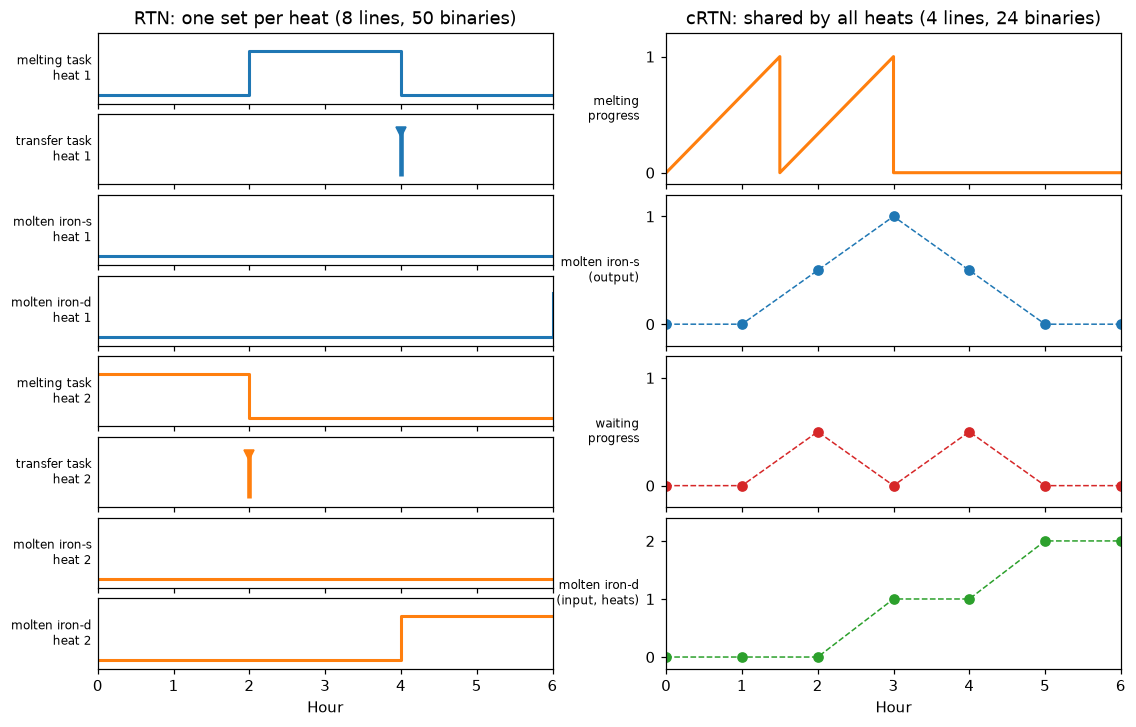

In [4]:
from matplotlib.gridspec import GridSpec

T = 6
hours = np.arange(T + 1)
fig = plt.figure(figsize=(12, 7.5))
gs = GridSpec(8, 2, figure=fig, hspace=0.15, wspace=0.25)

# RTN: one set of tasks and resources per heat
info = m_rtn._rtn
rtn_rows = []
for h in range(2):
    melt, trans = info["task_proc"](0, h), info["task_proc"](0, h) + 1
    status = [pyo.value(m_rtn.S[h, t]) for t in range(T)]
    rtn_rows += [
        (f"melting task\nheat {h + 1}", status + [status[-1]], "step"),
        (f"transfer task\nheat {h + 1}", [pyo.value(m_rtn.N[trans, t]) for t in range(T)] + [0], "start"),
        (f"molten iron-s\nheat {h + 1}", [pyo.value(m_rtn.R[1 + 2 * h, t]) for t in hours], "step"),
        (f"molten iron-d\nheat {h + 1}", [pyo.value(m_rtn.R[2 + 2 * h, t]) for t in hours], "step"),
    ]
for k, (label, values, kind) in enumerate(rtn_rows):
    ax = fig.add_subplot(gs[k, 0])
    color = "tab:blue" if k < 4 else "tab:orange"
    if kind == "start":
        starts = [t for t, v in enumerate(values) if v > 0.5]
        ax.vlines(starts, 0, 1, color=color, lw=3); ax.plot(starts, [1] * len(starts), "v", color=color)
    else:
        ax.step(hours, values, where="post", color=color, lw=2)
    ax.set_ylim(-0.2, 1.4); ax.set_yticks([]); ax.set_xlim(0, T)
    ax.set_ylabel(label, rotation=0, ha="right", va="center", fontsize=8)
    if k < 7:
        ax.set_xticklabels([])
    if k == 0:
        ax.set_title(f"RTN: one set per heat (8 lines, {fx.count_vars(m_rtn)[0]} binaries)")
ax.set_xlabel("Hour")

# cRTN: one set of tasks and resources, shared by all heats
t_melt, melt = crtn_progress(m_crtn, stage=0)
crtn_rows = [
    ("melting\nprogress", (t_melt, melt), "tab:orange"),  # within-slot reconstruction
    ("molten iron-s\n(output)", (hours, [pyo.value(m_crtn.R[1, t]) for t in hours]), "tab:blue"),
    ("waiting\nprogress", (hours, [pyo.value(m_crtn.R[2, t]) for t in hours]), "tab:red"),
    ("molten iron-d\n(input, heats)", (hours, [pyo.value(m_crtn.R[3, t]) for t in hours]), "tab:green"),
]
for k, (label, (x, y), color) in enumerate(crtn_rows):
    ax = fig.add_subplot(gs[2 * k:2 * k + 2, 1])
    if k == 0:
        ax.plot(x, y, color=color, lw=2); ax.set_ylim(-0.1, 1.2); ax.set_yticks([0, 1])
    else:  # levels at slot boundaries
        ax.plot(x, y, "o--", color=color, lw=1, ms=6)
        ax.set_ylim(-0.2, 2.4 if k == 3 else 1.2); ax.set_yticks([0, 1, 2] if k == 3 else [0, 1])
    ax.set_xlim(0, T)
    ax.set_ylabel(label, rotation=0, ha="right", va="center", fontsize=8)
    if k < 3:
        ax.set_xticklabels([])
    if k == 0:
        ax.set_title(f"cRTN: shared by all heats (4 lines, {fx.count_vars(m_crtn)[0]} binaries)")
ax.set_xlabel("Hour")
plt.show()

## 2. The steelmaking line

Four serial stages: EAF (85 MW, power-flexible 75–125%) → AOD → LF → continuous caster (CC). Use the sliders to change the day (PJM real-time prices, July 2022) and the number of heats. Both models are solved at **30-minute** slots so that each solve takes a few seconds.

In [5]:
steel = fx.load_batch_plant("steelmaking_zhang2017")
pd.DataFrame([vars(s) for s in steel.stages]).rename(columns={
    "power_mw": "power (MW)", "processing_min": "processing (min)",
    "transfer_min": "transfer (min)", "max_wait_min": "max wait (min)"})

,name,power (MW),processing (min),transfer (min),max wait (min)
0,EAF,85,80,10,120
1,AOD,2,75,5,120
2,LF,2,35,10,120
3,CC,7,50,0,0


In [6]:
from ipywidgets import interact, IntSlider

DT = 0.5  # hours per slot
prices = fx.load_prices("2022-07")

@interact(day=IntSlider(26, 1, 31, description="July day"), heats=IntSlider(2, 1, 3, description="heats"))
def show(day, heats):
    price = np.repeat(prices.iloc[day - 1].to_numpy(), int(1 / DT))
    rtn = fx.solve(fx.build_rtn(steel, price, heats, dt=DT))
    crtn = fx.solve(fx.build_crtn(steel, price, heats, dt=DT))
    fig, axes = plt.subplots(2, 1, figsize=(11, 6), sharex=True)
    viz.plot_schedule(rtn, price, dt=DT, ax=axes[0],
                      title=f"RTN:  ${rtn.cost:,.0f}, {rtn.n_binary} binaries, {rtn.solve_seconds:.1f} s")
    viz.plot_schedule(crtn, price, dt=DT, ax=axes[1],
                      title=f"cRTN: ${crtn.cost:,.0f}, {crtn.n_binary} binaries, {crtn.solve_seconds:.1f} s")
    plt.tight_layout(); plt.show()

interactive(children=(IntSlider(value=26, description='July day', max=31, min=1), IntSlider(value=2, descripti…

**Which heat is where, and when?** A Gantt chart of the same day (3 heats) shows the schedules directly. Both models push the energy-hungry EAF melting into the cheaper hours, but the cRTN can start and finish tasks within a slot, so it packs the heats more tightly. (The cRTN decides how long each task runs within a slot, not its exact start time; the chart places that time at the slot edge next to the neighboring activity.)

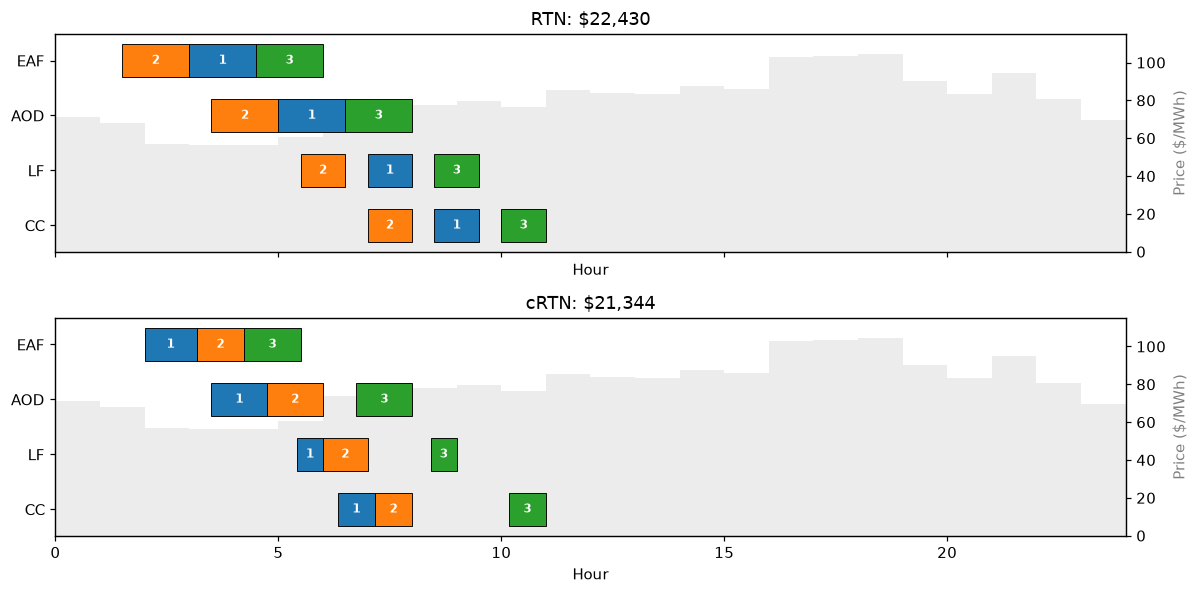

In [7]:
price = np.repeat(prices.iloc[25].to_numpy(), int(1 / DT))  # July 26
fig, axes = plt.subplots(2, 1, figsize=(11, 5.5), sharex=True)
for ax, (name, build) in zip(axes, [("RTN", fx.build_rtn), ("cRTN", fx.build_crtn)]):
    m = build(steel, price, 3, dt=DT)
    r = fx.solve(m)
    viz.plot_gantt(heat_schedule(m), [st.name for st in steel.stages], ax=ax, price=price, dt=DT,
                   title=f"{name}: ${r.cost:,.0f}")
plt.tight_layout(); plt.show()

## 3. Model size: binaries vs. the number of heats

This is the core idea of the cRTN. The conventional RTN creates tasks and resources **for every heat**, so its binary variables grow with the production target. The cRTN shares one set of tasks across all heats and tracks *progress* with continuous variables, so its binary count does not depend on the number of heats.

Counting variables only requires building the models, not solving them, so we can use the paper's **5-minute** resolution here:

model,RTN,cRTN
heats,,
1,4883,4608
2,8614,4608
3,12345,4608
4,16076,4608
5,19807,4608
6,23538,4608
7,27269,4608
8,31000,4608
9,34731,4608


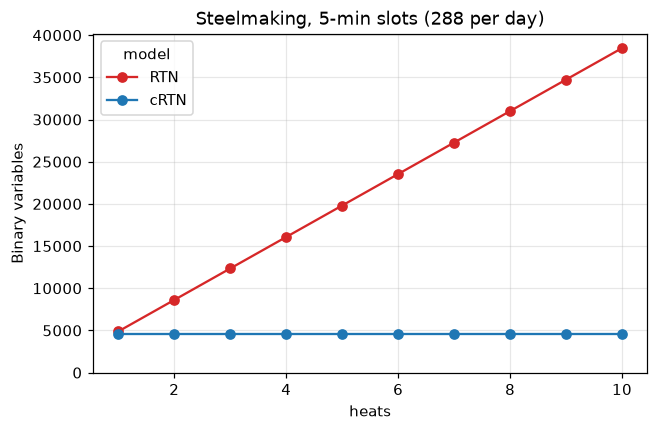

In [8]:
price_5min = np.repeat(fx.daily_price("2022-07", 26), 12)
rows = []
for heats in range(1, 11):
    for name, build in [("RTN", fx.build_rtn), ("cRTN", fx.build_crtn)]:
        nb, nc = fx.count_vars(build(steel, price_5min, heats, dt=1 / 12))
        rows.append({"model": name, "heats": heats, "binary": nb, "continuous": nc})
size = pd.DataFrame(rows)
display(size.pivot(index="heats", columns="model", values="binary"))

ax = size.pivot(index="heats", columns="model", values="binary").plot(
    marker="o", color={"RTN": "tab:red", "cRTN": "tab:blue"}, figsize=(6.5, 4))
ax.set_ylabel("Binary variables"); ax.set_title("Steelmaking, 5-min slots (288 per day)")
ax.set_ylim(0); ax.grid(alpha=0.3); plt.show()

## 4. Solve time as the number of heats grows

Fewer binaries do not guarantee a faster solve on every small case. With 1–3 heats, the RTN is small too and often solves faster. The difference appears as the production target grows. The cell below solves both models with the free HiGHS solver at 30-minute slots for 1–6 heats (about 2 minutes in total; each solve is capped at `TIME_LIMIT`). In our runs on a laptop, the cRTN stays under about 10 s, while the RTN overtakes it at around 4 heats and reaches the time limit at 6. The RTN's schedules also cost 3–8% more, because task durations are rounded up to whole slots. (At 6 heats the RTN was stopped at the time limit, so part of that gap is unfinished optimization.)

RTN  heats=1: optimal      0.2 s, cost $7,257


cRTN heats=1: optimal      0.6 s, cost $7,018


RTN  heats=2: optimal      0.4 s, cost $14,540


cRTN heats=2: optimal      0.6 s, cost $14,088


RTN  heats=3: optimal      1.8 s, cost $22,430


cRTN heats=3: optimal      4.2 s, cost $21,344


RTN  heats=4: optimal      6.0 s, cost $31,088


cRTN heats=4: optimal      5.4 s, cost $29,066


RTN  heats=6: time limit  45.3 s, cost $49,477


cRTN heats=6: optimal      8.6 s, cost $45,976


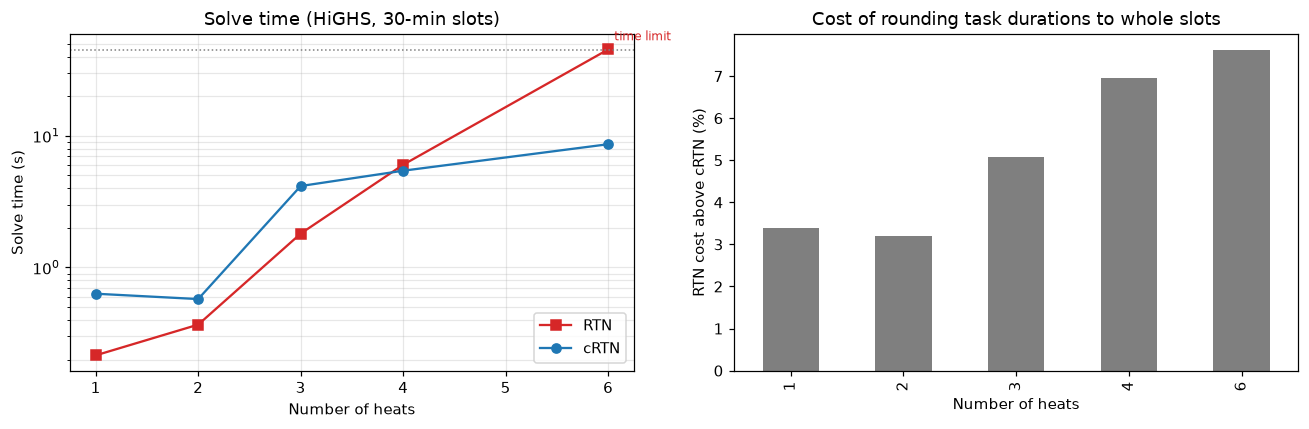

In [9]:
TIME_LIMIT = 45
HEATS = [1, 2, 3, 4, 6]
price_30min = np.repeat(fx.daily_price("2022-07", 26), 2)

rows = []
for heats in HEATS:
    for name, build in [("RTN", fx.build_rtn), ("cRTN", fx.build_crtn)]:
        r = fx.solve(build(steel, price_30min, heats, dt=0.5), time_limit=TIME_LIMIT)
        rows.append({"model": name, "n": heats, "seconds": r.solve_seconds, "status": r.status,
                     "binaries": r.n_binary, "cost": r.cost})
        print(f"{name:4s} heats={heats}: {r.status:10s} {r.solve_seconds:5.1f} s, cost ${r.cost:,.0f}")

timing = pd.DataFrame(rows)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
viz.plot_scaling(rows, time_limit=TIME_LIMIT, ax=axes[0], xlabel="Number of heats", log_x=False)
axes[0].set_title("Solve time (HiGHS, 30-min slots)")
gap = timing.pivot(index="n", columns="model", values="cost")
(100 * (gap["RTN"] - gap["cRTN"]) / gap["cRTN"]).plot.bar(ax=axes[1], color="tab:grey")
axes[1].set_ylabel("RTN cost above cRTN (%)"); axes[1].set_xlabel("Number of heats")
axes[1].set_title("Cost of rounding task durations to whole slots")
plt.tight_layout(); plt.show()

**At the paper's scale.** The thesis uses 5-minute slots, Gurobi, and up to 8 heats. There, the RTN's solve time grows roughly exponentially with the number of heats while the cRTN's grows roughly linearly; for 8 heats, the mean solve time over 15 July days falls from **156.7 to 17.1 minutes (−89%)**. This is a different test case from the LSTN scaling result in notebook 01. To try it yourself with Gurobi (`pip install gurobipy` plus a license), set `RUN_GUROBI = True`. Expect minutes per solve.

In [10]:
RUN_GUROBI = False

if RUN_GUROBI:
    price_5min = np.repeat(fx.daily_price("2022-07", 26), 12)
    for heats in [2, 4, 8]:
        for name, build in [("RTN", fx.build_rtn), ("cRTN", fx.build_crtn)]:
            r = fx.solve(build(steel, price_5min, heats, dt=1 / 12), solver="gurobi", mip_gap=1e-4, time_limit=1800)
            print(f"{name:4s} heats={heats}: {r.summary()}")

## 5. How the cRTN relates to the LSTN

Both models replace **"which state is the machine in during this slot?"** (binary) with **"how long does it spend in each state?"** (continuous). For continuous processes that removes every binary (LSTN). Batch processes still need a few status binaries for the uninterruptible and waiting logic, but no longer one per heat (cRTN). In the thesis (Ch. 2 §2.5.5), the STN is shown to be a special case of the RTN, and the LSTN a special case of the cRTN.

## 6. Things to try

1. Make the EAF inflexible: `dataclasses.replace(steel, power_ratio=(1.0, 1.0))`. How much of the cost saving disappears?
2. Change `DT` in Section 2 to `0.25`. The RTN's rounding error shrinks, but its model grows.
3. Tighten the waiting limit of the LF stage and watch the schedule compress.

**Takeaways**
* The cRTN keeps the batch logic (uninterruptible melting, waiting limits) but its size does not grow with the number of heats.
* It avoids the RTN's rounding of task durations to whole slots, which changes the cost even in a one-furnace example.
* The cRTN reduces binaries; it does not remove them all. Its solve-time advantage is a statement about growing problems (many heats, fine slots), not every small case.
* Next in the chain: what if we *don't know* the plant's parameters? → **notebook 03: parameter identification (PSI)**.